<a href="https://colab.research.google.com/github/embark-cybertraining/embark-scratch-notebooks/blob/main/sessions_1_and_2/ooi_cruises_bcodmo_argo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2026-10-14 Updated Session 2 only
# Prototype combined notebook for EMBARK CyberTraining Sessions 1 and 2

## Use Case Goal:

An oceanographer would like to visualize salinity by depth at a deep ocean study site with multiple cruises over several years.
As a CI user, s/he will (find), access, and use data from external sources to plot salinity by depth over a several-year time period for a location in which some of the profiles were collected by ship-based CTD rosette casts and others were sensed by Argo floats.

* Data repositories: BCO-DMO, NCEI
* Ocean observing systems: Argo, U.S. NSF OOI

* Tools include: ERDDAP, Python software libraries (e.g., pandas, erddapy, argopy)

This notebook may be run locally, or within cloud-based computing infrastructure (e.g., Google Colab, OOI JupyterHub).

## Session 1
Visualize 10 years of discrete water sampling data from annual research cruises and overlay with post-calibrated, ship-cast CTD profiles
## Session 2
Fill in the time gaps between research cruises with CTD profile data from autonomous floats

## Credits for this notebook
* The first portion builds on a notebook from the OOI CGSN Data Team https://github.com/WHOIGit/ooi-on-bco-dmo/blob/main/notebooks/0-OOI-Irminger-discrete-sample-article-figures.ipynb
* Overall the notebook was developed by the EMBARK CyberTraining project team, including Amber York, Sage Lichtenwalner, and Stace Beaulieu.
* Where indicated, some code was generated or improved by AI coding assistance, including ChatGPT.

# Setup

In [ ]:
#install libraries directly into the current kernel's environment if dependency not found
try:
    import argopy
except ImportError:
    %pip install -q argopy

try:
    import cmocean.cm as cmo
except ImportError:
    %pip install -q cmocean

# consider remove the cmocean package and just use viridis

In [ ]:
# Import modules
# note this does not yet include folium for Session 1
# does not yet include argopy, plotly, numpy for Session 2
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from matplotlib.dates import AutoDateLocator, AutoDateFormatter
import cmocean.cm as cmo # colormaps for commonly-used oceanographic variables

In [ ]:
# print(mpl.__version__) # if plot cell results in error check version of matplotlib

# SESSION 1
Visualize 10 years of discrete water sampling data from annual research cruises and overlay with post-calibrated, ship-cast CTD profiles

We will use cruises to the U.S. NSF OOI Global Irminger Sea Array https://oceanobservatories.org/array/global-irminger-sea-array/.

Discrete water samples were collected not only for post-cal'g ship-cast CTD sensors but also for in situ mooring-mounted sensors.

# DATASET 1 - Discrete water sampling data from research cruises

## Find Data
The CI user already will have used other tools to search for "Irminger Sea discrete water sampling" and find:
* Dataset: OOI Global Irminger Sea Array CTD and Discrete Water Sampling Data from Mooring Overturning Cruises in the Irminger Sea from 2014-2023 (OOI Cruise Data project)
* **Dataset Landing Page: https://www.bco-dmo.org/dataset/911407**



## Inspect data/metadata for context


Inspect the dataset landing page metadata for context for your analysis.

This dataset also is provided through ERDDAP; you can use the ERDDAP Make A Graph tool to confirm your desired location, time period, and parameters are in the dataset: https://erddap.bco-dmo.org/erddap/tabledap/bcodmo_dataset_911407_v1.graph




### Review the data license

Check the license to make sure your intended use is allowed.

## Access Data without downloading the file

### Load entire Discrete water sampling data table using HTTPS URL


To access the data in comma separated variable (CSV) format, one can either:
1. Access the File through the URL on the Dataset Landing Page
2. Access the File through the URL at ERDDAP > Files
3. Generate a URL using the [ERDDAP Data Access Form](https://erddap.bco-dmo.org/erddap/tabledap/bcodmo_dataset_911407_v1.html)
      - If using the ERDDAP Data Access Form, file type .csvp provides a single header row.
      - Note: If using the ERDDAP Data Access Form, one can subset (e.g., select variables of interest, and ranges within variables) prior to loading the data.

In [ ]:
# link to the public dataset CSV
# 1. not tested yet
# https://datadocs.bco-dmo.org/dataset/911407/file/vmvAX9NU4gqY2V/911407_v1_ooi_irminger_sea_discrete_water_sampling_data.csv
# 2.
erddap_url = "https://erddap.bco-dmo.org/erddap/files/bcodmo_dataset_911407_v1/911407_v1_ooi_irminger_sea_discrete_water_sampling_data.csv"

# Load the OOI data into a dataframe
ooi_irm = pd.read_csv(erddap_url)

# Call head() to check that the data was imported correctly
ooi_irm.head()

note the first rows of the data indicate a test cast outside of our desired study area

In [ ]:
# List available parameters
print(ooi_irm.columns)

## Transform data (if needed)
Convert relevant parameters to datetime if needed

In [ ]:
# Convert the CTD Bottle Closure Time to a datetime data type
ooi_irm["CTD_Bottle_Closure_Time"] = pd.to_datetime(ooi_irm["CTD_Bottle_Closure_Time"], yearfirst=True, utc=True)
ooi_irm.dtypes["CTD_Bottle_Closure_Time"]

## Apply QC flags
For functions to interpret OOI discrete sample CTD flags to QARTOD QC-flags please see bottles.py file in https://github.com/oceanobservatories/ooi-data-explorations.

In [ ]:
# display unique Discrete Sample flags
ooi_irm.Discrete_Salinity_Flag.unique() # display unique for parameter of interest
# pd.unique(ooi_irm[["Discrete_Oxygen_Flag", "Discrete_Salinity_Flag", "Discrete_Nutrients_Flag"]].values.ravel('K')) # display unique multiple columns

In [ ]:
# Assign "Acceptable" flags to QARTOD
flag1 = "*0000000000000100" # Good 1 in Bit Position 2 (i.e., 3rd from right)
flag2 = "*0000000000000101" # this example had 2 unique "Acceptable" flags

#ooi_irm.loc[ooi_irm.Discrete_Oxygen_Flag == flag1, 'Discrete_Oxygen_Flag'] = 1       # assign QARTOD Good
#ooi_irm.loc[ooi_irm.Discrete_Oxygen_Flag == flag2, 'Discrete_Oxygen_Flag'] = 1       # assign QARTOD Good
ooi_irm.loc[ooi_irm.Discrete_Salinity_Flag == flag1, 'Discrete_Salinity_Flag'] = 1   # assign QARTOD Good
ooi_irm.loc[ooi_irm.Discrete_Salinity_Flag == flag2, 'Discrete_Salinity_Flag'] = 1   # assign QARTOD Good
#ooi_irm.loc[ooi_irm.Discrete_Nutrients_Flag == flag1, 'Discrete_Nutrients_Flag'] = 1 # assign QARTOD Good
#ooi_irm.loc[ooi_irm.Discrete_Nutrients_Flag == flag2, 'Discrete_Nutrients_Flag'] = 1 # assign QARTOD Good

# again display unique Discrete Sample flags
ooi_irm.Discrete_Salinity_Flag.unique() # display unique for parameter of interest
#pd.unique(ooi_irm[["Discrete_Oxygen_Flag", "Discrete_Salinity_Flag", "Discrete_Nutrients_Flag"]].values.ravel('K')) # display unique multiple columns


In [ ]:
# Subset Data Frame to Discrete Samples with Acceptable flags
irm_qc = ooi_irm.query("Discrete_Salinity_Flag==1")

#irm_qc = ooi_irm.query("Discrete_Oxygen_Flag==1 | Discrete_Salinity_Flag==1 | Discrete_Nutrients_Flag==1")
print(f"This subset of Discrete Samples with Acceptable flags reduced the total data points from {len(ooi_irm)} to {len(irm_qc)}")

In [ ]:
# Call head() to view subset of Discrete Samples with Acceptable flags
irm_qc.head()

note the first rows of this particular subset of data still indicate a test cast outside of our desired study area


If we do not subset to our desired region of interest, the first plot over time that we make below will include irrelevant data.
We could proceed with the next code cell to subset to our desired region of interest.

In [ ]:
# For indexing plots with matplotlib
#flag_oxy = irm_qc["Discrete_Oxygen_Flag"]==1
flag_sal = irm_qc["Discrete_Salinity_Flag"]==1
#flag_ntr = irm_qc["Discrete_Nutrients_Flag"]==1

In [ ]:
# # Keep this cell to demonstrate efficiency using ERDDAP to subset prior to loading data
# # Use code within notebook to subset to just the area (and time) of interest
# # Bounds
# LON_MIN, LON_MAX = -40, -39
# LAT_MIN, LAT_MAX = 59.5, 60.5
# TIME_MIN, TIME_MAX = "2018-01-01", "2021-12-31"

# # Ensure we are not working on a view
# irm_qc = irm_qc.copy()

# irm_qc.loc[:, "CTD_Bottle_Closure_Time"] = pd.to_datetime(
#     irm_qc["CTD_Bottle_Closure_Time"], yearfirst=True, utc=True, errors="coerce"
# )

# tmin = pd.to_datetime(TIME_MIN, utc=True)
# tmax = pd.to_datetime(TIME_MAX, utc=True)

# ooi_subset = irm_qc.loc[
#     (irm_qc["CTD_Bottle_Closure_Time"] >= tmin) &
#     (irm_qc["CTD_Bottle_Closure_Time"] <= tmax) &
#     (irm_qc["Start_Latitude"] >= LAT_MIN) &
#     (irm_qc["Start_Latitude"] <= LAT_MAX) &
#     (irm_qc["Start_Longitude"] >= LON_MIN) &
#     (irm_qc["Start_Longitude"] <= LON_MAX)
# ].copy().reset_index(drop=True)

# ooi_subset

# # Would need to recompute QC masks on the subset (moved to below)

## Visualize data

##### Set themes, styles, and figure global parameters

In [ ]:
# Assign colormaps from cmocean package
#cmap_oxy = cmo.deep_r
cmap_salt = cmo.haline
#cmap_nitr = cmo.matter
#cmap_chl = cmo.algae
cmap_time = cmo.tempo_r

In [ ]:
# set up time for matplotlib plots
discrete_time = irm_qc["CTD_Bottle_Closure_Time"].values

# Create a matplotlib-friendly numeric time array
discrete_mpl_time = mpl.dates.date2num(discrete_time)

# Create normalizer for colorbar representing the full date range
normalizer = Normalize(discrete_mpl_time[0], discrete_mpl_time[-1])

# Create tick locator for using time as the color scale
locator = AutoDateLocator()

In [ ]:
# determine max min for parameter of interest
salmax = irm_qc["Discrete_Salinity"].max()
salmin = irm_qc["Discrete_Salinity"].min()
print(f"Max: {salmax} | Min: {salmin}")

# # compare to ooi_subset if execute commented cell above
# # much narrower range
# salmax = ooi_subset["Discrete_Salinity"].max()
# salmin = ooi_subset["Discrete_Salinity"].min()
# print(f"Max: {salmax} | Min: {salmin}")


#### Plot QC'd Data

**Figure** Plot the salinity over time as a function of depth

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.invert_yaxis()
plt.scatter(x=discrete_time[flag_sal], y=irm_qc["CTD_Pressure"][flag_sal], s=20,
            c=irm_qc["Discrete_Salinity"][flag_sal], cmap=cmap_salt,
            edgecolors="none", vmin=salmin, vmax=salmax)
plt.grid()
plt.colorbar(label="Salinity [psu]", extend='both')
ax.set_ylabel("Pressure [dbar]")
ax.set_xlabel("Time")

Dataset 1: Quick map visualization prior to geographic subsetting

Note: this activity is situated at the end of Session 1: 1st breakout; it would more naturally fit earlier but we want the 1st breakout to achieve the salinity by depth plot.

In [ ]:
# code in this cell was generated by ChatGPT
import folium
from folium import LatLngPopup

# Remove rows with missing coordinates
df = irm_qc.dropna(subset=["Start_Latitude", "Start_Longitude"])

# Center map on the average location
center_lat = df["Start_Latitude"].mean()
center_lon = df["Start_Longitude"].mean()

m = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=8
)

# Add points
for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row["Start_Latitude"], row["Start_Longitude"]],
        radius=3,
        color="blue",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m.add_child(LatLngPopup())

m

## Access a subset of data using a URL pattern


### Generate a URL using the [ERDDAP Data Access Form](https://erddap.bco-dmo.org/erddap/tabledap/bcodmo_dataset_911407_v1.html)
If using the ERDDAP Data Access Form, file type .csvp provides a single header row.

If using the ERDDAP Data Access Form, one can subset (e.g., select variables of interest, and ranges within) prior to loading the data.

In [ ]:
# load ooi_subset from ERDDAP
# then do steps above for disc sal qc to make this new dataframe equivalent to relevant content within ooi_subset from coding within cell above
erddap_url = "https://erddap.bco-dmo.org/erddap/tabledap/bcodmo_dataset_911407_v1.csvp?Cruise%2CTarget_Asset%2CStart_Latitude%2CStart_Longitude%2CStart_Time%2CCast%2CNiskin_Bottle_Position%2CCTD_Bottle_Closure_Time%2CCTD_Pressure%2CCTD_Pressure_Flag%2CDiscrete_Salinity%2CDiscrete_Salinity_Flag&Start_Latitude%3E=59.5&Start_Latitude%3C=60.5&Start_Longitude%3E=-40&Start_Longitude%3C=-39"
# Load the data subset into a dataframe
ooi_subset = pd.read_csv(erddap_url)

# Call head() to check that the data was read in correctly
ooi_subset.head()

In [ ]:
ooi_subset.columns.tolist()

In [ ]:
# account for any NAs in ooi_subset["CTD_Bottle_Closure_Time (unitless)"]
#len(ooi_subset["CTD_Bottle_Closure_Time (unitless)"])
ooi_subset = ooi_subset.dropna(subset=["CTD_Bottle_Closure_Time (unitless)"])
len(ooi_subset["CTD_Bottle_Closure_Time (unitless)"])

In [ ]:
# Convert the CTD Bottle Closure Time to a datetime data type
ooi_subset["CTD_Bottle_Closure_Time (unitless)"] = pd.to_datetime(ooi_subset["CTD_Bottle_Closure_Time (unitless)"], yearfirst=True, utc=True)
ooi_subset.dtypes["CTD_Bottle_Closure_Time (unitless)"]

## Repeat transform

## Repeat apply QC flags

In [ ]:
# #  We have to recalculate the flags for the mask to be in the correct positions for the subset

# # Recompute QC masks on the subset
# ooi_flag_oxy = ooi_subset["Discrete_Oxygen_Flag"] == 1
# ooi_flag_sal = ooi_subset["Discrete_Salinity_Flag"] == 1
# ooi_flag_ntr = ooi_subset["Discrete_Nutrients_Flag"] == 1

# print("OOI subset salinity-flagged good rows:", int(ooi_flag_sal.sum()))

## Repeat visualize

In [ ]:
# steps as above but for new dataframe
# set up time for matplotlib plots (subset of data)
discrete_time_subset = ooi_subset["CTD_Bottle_Closure_Time (unitless)"].values

# Create a matplotlib-friendly numeric time array
discrete_mpl_time_subset = mpl.dates.date2num(discrete_time_subset)

# Create normalizer for colorbar representing the full date range
normalizer_subset = Normalize(discrete_mpl_time_subset[0], discrete_mpl_time_subset[-1])

# Create tick locator for using time as the color scale
locator_subset = AutoDateLocator()



In [ ]:
# determine max min for parameter of interest
salmax = ooi_subset["Discrete_Salinity (psu)"].max()
salmin = ooi_subset["Discrete_Salinity (psu)"].min()
print(f"Max: {salmax} | Min: {salmin}")


In [ ]:
# plot code from JP class differs from initial plot code above
plt.figure(figsize=(8, 5))

plt.scatter(
    x=ooi_subset["CTD_Bottle_Closure_Time (unitless)"],
    y=ooi_subset["CTD_Pressure (db)"],
    s=20,
    c=ooi_subset["Discrete_Salinity (psu)"],
    cmap=cmo.haline,  # colormap from cmocean, designed for salinity (perceptually uniform, accessible colors)
    edgecolors="none",
    vmin=34.8, # use salmin
    vmax=35 # use salmax
)

plt.gca().invert_yaxis()
plt.grid()
plt.colorbar(label="Salinity [psu]", extend="both")
plt.ylabel("Pressure [dbar]")
plt.xlabel("Time")
plt.title("Discrete salinity (geographic subset of interest)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

## Access a subset of data using erddapy


### Extract same subset without having to create a long URL

In [ ]:
# use erddapy to extract same subset as URL pattern

## Dataset 1: Record your data citation

Record a data citation for the source data you used. You can get the template for citing the data (or subset) used by clicking the "Cite Dataset" button on the dataset landing page.

# SUPPLEMENTARY DATASET for Session 1
*   Overlay one post-calibrated CTD profile via static NCEI URL
*   Overlay all matching post-calibrated CTD profiles downloaded from NCEI (requires additional notebook)




# SESSION 2
Fill in the time gaps between research cruises with CTD profile data from autonomous floats

# DATASET 2 - Argo float profiles

## Find data

The CI user already will have found argopy, a tool to find, access, and use Argo float data.

Argopy documentation indicates the default data source is:

https://erddap.ifremer.fr/erddap/info/ArgoFloats/index.html

## Inspect data/metadata for context

### Review the data license

Check the license to make sure your intended use is allowed.

## Setup


In [2]:
#install libraries required for Session 2
%pip install -q argopy cmocean

Note: you may need to restart the kernel to use updated packages.


In [3]:
#import libraries required for Session 2
from argopy import DataFetcher # https://argopy.readthedocs.io/en/latest/generated/argopy.fetchers.ArgoDataFetcher.html
import pandas as pd
import matplotlib.pyplot as plt
import cmocean.cm as cmo

## Access data


In [4]:
# Setup argopy DataFetcher to query Argo data ('phy' default or 'bgc' dataset) for a given space/time region
#f = DataFetcher().region([-40, -39, 59.5, 60.5, 0, 1000, '2014-01-01', '2024-12-31']) # to 1000 m with default source erddap and default standard mode
#f = DataFetcher(mode='research').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with default source erddap and research mode
#f = DataFetcher(src='gdac').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with source GDAC and default standard mode
f = DataFetcher(mode='research', src='gdac').region([-40, -39, 59.5, 60.5, 0, 5000, '2014-01-01', '2024-12-31']) # to 5000 m with source GDAC and research mode

(<Figure size 900x540 with 1 Axes>,
 <Axes: xlabel='longitude', ylabel='latitude'>)

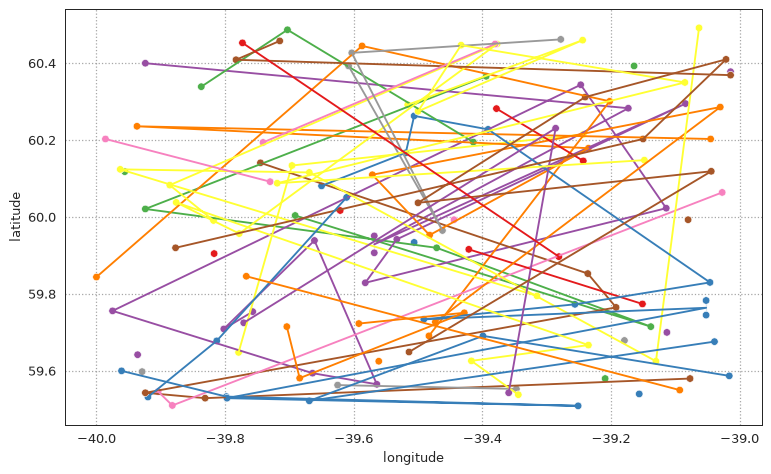

In [5]:
# The DataFetcher method has a quick method to plot profile trajectories
f.plot('trajectory')

The DataFetcher method does not load the data, it just creates an index.  There are a number of ways we can load either the full dataset or just the index into memory, but depending on how much data you have, it could take quite a while.  [Reference](https://argopy.readthedocs.io/en/latest/user-guide/fetching-argo-data/index.html)

In [6]:
%%time
# Load the data into a pandas DataFrame.  This can take a long time if you request a lot of data.
# How much time does this take? (4 minutes for GDAC 1 deg)
df_argo_profiles = f.to_dataframe().reset_index()

# "internally, Argopy often works with xarray and the implementation of to_dataframe()
# converts the loaded dataset to a DataFrame before returning it.
# So while you can use a DataFrame directly, under the hood xarray may still be involved."

#"For many Argo workflows (e.g., extracting temperature/salinity profiles and doing statistical analysis),
# a DataFrame is perfectly fine and often more convenient.
# For gridding, interpolation, or working with profile dimensions, xarray is usually the better choice."

# # Call head() to view top of data frame
# df_argo_profiles.head()
df_argo_profiles


CPU times: user 2min 4s, sys: 21.5 s, total: 2min 26s
Wall time: 4min 4s


,N_POINTS,CYCLE_NUMBER,DIRECTION,PLATFORM_NUMBER,PRES,PRES_ERROR,PSAL,PSAL_ERROR,TEMP,TEMP_ERROR,TIME,LATITUDE,LONGITUDE
0,0,40,A,6901489,3.100000,2.4,34.941002,0.010,4.944,0.002,2014-01-17 14:33:00,60.19476,-39.413708
1,1,40,A,6901489,3.200000,2.4,34.941002,0.010,4.945,0.002,2014-01-17 14:33:00,60.19476,-39.413708
2,2,40,A,6901489,3.500000,2.4,34.942001,0.010,4.945,0.002,2014-01-17 14:33:00,60.19476,-39.413708
3,3,40,A,6901489,3.700000,2.4,34.941002,0.010,4.945,0.002,2014-01-17 14:33:00,60.19476,-39.413708
4,4,40,A,6901489,3.800000,2.4,34.939999,0.010,4.945,0.002,2014-01-17 14:33:00,60.19476,-39.413708
...,...,...,...,...,...,...,...,...,...,...,...,...,...
54133,54133,110,A,6903041,2792.500000,3.2,34.893211,0.006,1.479,0.002,2024-06-17 15:39:00,59.89727,-39.280600
54134,54134,110,A,6903041,2793.699951,3.2,34.893211,0.006,1.478,0.002,2024-06-17 15:39:00,59.89727,-39.280600
54135,54135,110,A,6903041,2794.399902,3.2,34.893200,0.006,1.478,0.002,2024-06-17 15:39:00,59.89727,-39.280600
54136,54136,110,A,6903041,2795.600098,3.2,34.893200,0.006,1.478,0.002,2024-06-17 15:39:00,59.89727,-39.280600


In [7]:
%%time
# We can also load just the index into a pandas DataFrame, which is much faster.
df_index = f.index
df_index.head()

CPU times: user 1.58 ms, sys: 60 μs, total: 1.64 ms
Wall time: 1.61 ms


,file,date,latitude,longitude,ocean,profiler_code,institution,date_update,wmo,cyc,institution_name,dac,profiler
0,aoml/4902118/profiles/D4902118_082.nc,2018-08-27 03:10:09,60.400,-39.924,A,854,AO,2025-06-10 15:50:35,4902118,82,"AOML, USA",aoml,S2A float with SBE conductivity sensor
1,aoml/4902118/profiles/D4902118_087.nc,2018-10-15 19:30:07,60.283,-39.173,A,854,AO,2025-06-10 15:50:36,4902118,87,"AOML, USA",aoml,S2A float with SBE conductivity sensor
2,aoml/4902118/profiles/D4902118_088.nc,2018-10-25 18:04:08,59.907,-39.568,A,854,AO,2025-06-10 15:50:36,4902118,88,"AOML, USA",aoml,S2A float with SBE conductivity sensor
3,aoml/4902118/profiles/D4902118_091.nc,2018-11-24 13:43:47,60.295,-39.084,A,854,AO,2025-06-10 15:50:37,4902118,91,"AOML, USA",aoml,S2A float with SBE conductivity sensor
4,aoml/4902118/profiles/D4902118_092.nc,2018-12-04 12:11:38,59.942,-39.533,A,854,AO,2025-06-10 15:50:37,4902118,92,"AOML, USA",aoml,S2A float with SBE conductivity sensor


In [8]:
%%time
# We can touch on xarray in Session 2 as motivation for covering it in Session 4.
# Load the data into an xarray Dataset.  This can take a long time if you request a lot of data.
# How much time does this take?
ds_data = f.data # calls on DataFetcher.to_xarray() if not already in memory
ds_data

# compare timing to loading as data frame
# compare the cell output below to the output when displaying data frame above

CPU times: user 2.19 ms, sys: 0 ns, total: 2.19 ms
Wall time: 2.21 ms


<xarray.Dataset> Size: 4MB
Dimensions:          (N_POINTS: 54138)
Coordinates:
  * N_POINTS         (N_POINTS) int64 433kB 0 1 2 3 ... 54134 54135 54136 54137
    TIME             (N_POINTS) datetime64[ns] 433kB 2014-01-17T14:33:00 ... ...
    LATITUDE         (N_POINTS) float64 433kB 60.19 60.19 60.19 ... 59.9 59.9
    LONGITUDE        (N_POINTS) float64 433kB -39.41 -39.41 ... -39.28 -39.28
Data variables:
    CYCLE_NUMBER     (N_POINTS) int64 433kB 40 40 40 40 40 ... 110 110 110 110
    DIRECTION        (N_POINTS) <U1 217kB 'A' 'A' 'A' 'A' ... 'A' 'A' 'A' 'A'
    PLATFORM_NUMBER  (N_POINTS) int64 433kB 6901489 6901489 ... 6903041 6903041
    PRES             (N_POINTS) float32 217kB 3.1 3.2 ... 2.796e+03 2.796e+03
    PRES_ERROR       (N_POINTS) float32 217kB 2.4 2.4 2.4 2.4 ... 3.2 3.2 3.2
    PSAL             (N_POINTS) float32 217kB 34.94 34.94 34.94 ... 34.89 34.89
    PSAL_ERROR       (N_POINTS) float32 217kB 0.01 0.01 0.01 ... 0.006 0.006
    TEMP             (N_POINTS) float32 217kB 4.944 4.945 4.945 ... 1.478 1.477
    TEMP_ERROR       (N_POINTS) float32 217kB 0.002 0.002 0.002 ... 0.002 0.002
Attributes:
    DATA_ID:              ARGO
    DOI:                  http://doi.org/10.17882/42182
    Fetched_by:           jovyan
    Fetched_constraints:  [x=-40.00/-39.00; y=59.50/60.50; z=0.0/5000.0; t=20...
    Fetched_date:         2026/10/14
    Fetched_from:         https://data-argo.ifremer.fr
    Fetched_uri:          https://data-argo.ifremer.fr/dac/bodc/6901199/69011...
    Processing_history:   Transformed with 'profile2point'; URI merged with '...
    raw_attrs:            {'title': 'Argo float vertical profile', 'instituti...

In [ ]:
# if we start by loading with xarray, we can convert to data frame
# And can convert the 1D point data to a data frame
df_argo = ds_data.to_dataframe()
df_argo = df_argo.reset_index()
df_argo

# is df_argo equiv to df_argo_profiles ?

In [ ]:
# Save full Argo dataframe (just in case)
#df_argo.to_csv("argo_subset_points.csv", index=False)

In [ ]:
# disaster recovery option
#df_argo = pd.read_csv("argo_subset_points.csv")
#df_argo

##  Transform data (if needed)

## Apply QC Flags (if applicable)

## Visualize Data

In [9]:
# Assign colormaps from cmocean package
cmap_salt = cmo.haline
cmap_time = cmo.tempo_r

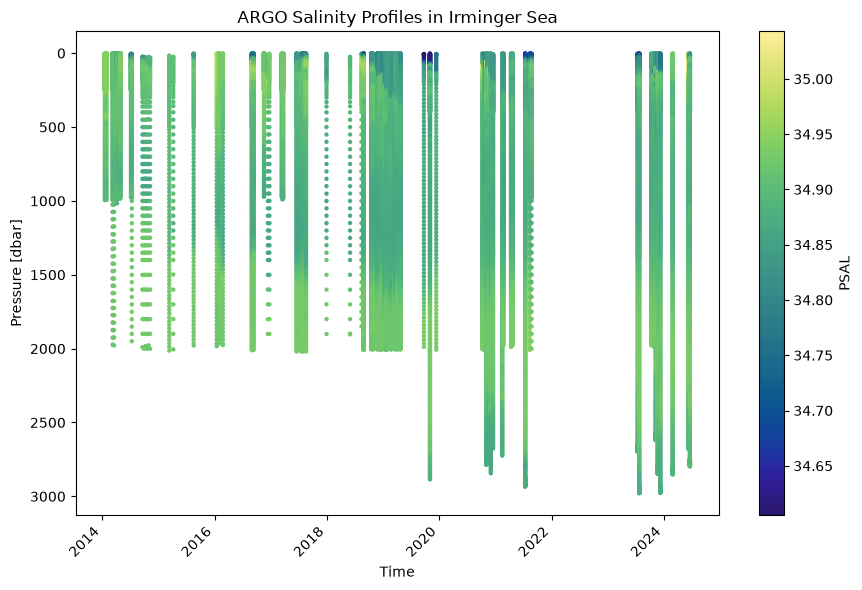

In [10]:
#using matplotlib

# this is using data frame
df_argo_profiles["TIME"] = pd.to_datetime(
    df_argo_profiles["TIME"], utc=True, errors="coerce"
)

# Drop rows missing the fields needed for plotting
c = df_argo_profiles.dropna(
    subset=["TIME", "PRES", "PSAL"]
).copy()

fig, ax = plt.subplots(figsize=(9, 6))

sc = ax.scatter(
    c["TIME"],
    c["PRES"],
    c=c["PSAL"],
    s=10,
    cmap=cmap_salt,
    #alpha=0.25,
    edgecolors="none"
)

ax.invert_yaxis()
ax.set_title("ARGO Salinity Profiles in Irminger Sea")
ax.set_xlabel("Time")
ax.set_ylabel("Pressure [dbar]")

# Rotate time labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("PSAL")

plt.tight_layout()
plt.show()

In [ ]:
# note this is using the xarray data array
#import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))
#sc = ax.scatter(x=ds_data['TIME'], y=ds_data['PRES'], c=ds_data['TEMP'], s=1, cmap='plasma')
sc = ax.scatter(x=ds_data['TIME'], y=ds_data['PRES'], c=ds_data['PSAL'], s=1, cmap=cmap_salt)
#fig.colorbar(sc, ax=ax, label='Temperature (°C)')
fig.colorbar(sc, ax=ax, label='PSAL')

#ax.set_title('ARGO Temperature Profiles in Irminger Sea')
ax.set_title('ARGO Salinity Profiles in Irminger Sea')
ax.set_ylabel('Pressure (dbar)')
ax.invert_yaxis()
fig.autofmt_xdate()
plt.show()

## Dataset 2: Record your data citation

# BOTH DATASETS


## Inspect data/metadata together

For our usecase we want to know if we can use the salinity from both datsets together. Let's look at the documentation again and pull out what the salinity, pressure, lat, lon, and time reported in both datasets.  See if the type of measurement and units are compatible to use together.


In [ ]:
# The OOI discrete dataset from BCO-DMO was loaded as a data frame that just has values (no metadata),
# so we have to look at the dataset landing page (or the lower part of the BCO-DMO ERDDAP dataset page).

# (Similarly for the Argo data frame you could look at the lower part of the Argo ERDDAP dataset page.)
# The Argo xarray dataset contains metadata
ds_data["PSAL"].attrs

 ## Visualize together

In [ ]:
#import matplotlib.pyplot as plt

# Unpack figure and axis
fig, ax = f.plot("trajectory")

# # Subset to good salinity OOI samples
# ooi_pts = ooi_subset.loc[ooi_flag_sal].copy()

# # Overlay OOI discrete points
# ax.scatter(
#     ooi_pts["Start_Longitude"],
#     ooi_pts["Start_Latitude"],
#     s=70,
#     facecolors="none",
#     edgecolors="cyan",
#     linewidths=1.8,
#     zorder=5,
#     label="OOI discrete"
# )

# Overlay OOI discrete points
ax.scatter(
    ooi_subset["Start_Longitude (decimal degrees)"],
    ooi_subset["Start_Latitude (decimal degrees)"],
    s=70,
    facecolors="none",
    edgecolors="cyan",
    linewidths=1.8,
    zorder=5,
    label="OOI discrete"
)

# Axis labels
ax.set_xlabel("Longitude", labelpad=15)
ax.set_ylabel("Latitude", labelpad=15)

# Title
ax.set_title("Argo Trajectories with OOI Discrete Salinity Samples", pad=15)

# Legend outside right
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    borderaxespad=0
)

# Make space for legend
plt.subplots_adjust(right=0.8)

plt.show()

In [ ]:
# Time vs. pressure, colored by salinity
# Argo profiles underneath, CTD discrete samples on top

#import matplotlib.pyplot as plt
#import pandas as pd

# Ensure datetime
ooi_subset["CTD_Bottle_Closure_Time (unitless)"] = pd.to_datetime(
    ooi_subset["CTD_Bottle_Closure_Time (unitless)"], utc=True, errors="coerce"
)
df_argo_profiles["TIME"] = pd.to_datetime(
    df_argo_profiles["TIME"], utc=True, errors="coerce"
)

# Drop rows missing the fields needed for plotting
d = ooi_subset.dropna(
    subset=["CTD_Bottle_Closure_Time (unitless)", "CTD_Pressure (db)", "Discrete_Salinity (psu)"]
).copy()

c = df_argo_profiles.dropna(
    subset=["TIME", "PRES", "PSAL"]
).copy()

fig, ax = plt.subplots(figsize=(7, 6))

# Argo underneath
sc = ax.scatter(
    c["TIME"],
    c["PRES"],
    c=c["PSAL"],
    s=10,
    #alpha=0.25,
    edgecolors="none"
)

# CTD discrete on top
ax.scatter(
    d["CTD_Bottle_Closure_Time (unitless)"],
    d["CTD_Pressure (db)"],
    c=d["Discrete_Salinity (psu)"],
    s=55,
    alpha=0.9,
    edgecolors="k",
    linewidths=0.5
)

ax.invert_yaxis()
ax.set_title("Time vs pressure (color = salinity)\nArgo under, CTD discrete over")
ax.set_xlabel("Time")
ax.set_ylabel("Pressure [dbar]")

# Rotate time labels
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Salinity")

plt.tight_layout()
plt.show()

## Same plot with plotly

In [ ]:
import plotly.graph_objects as go
#import pandas as pd # imported at top of notebook
import numpy as np # needed for sal_min

# already did this for matplotlib
# # Ensure datetime
# df_ctd_discrete["CTD_Bottle_Closure_Time (unitless)"] = pd.to_datetime(
#     df_ctd_discrete["CTD_Bottle_Closure_Time (unitless)"], utc=True, errors="coerce"
# )
# df_argo_profiles["TIME"] = pd.to_datetime(
#     df_argo_profiles["TIME"], utc=True, errors="coerce"
# )

# # already did this for matplotlib
# # Drop rows missing the fields needed for plotting
# d = df_ctd_discrete.dropna(
#     subset=["CTD_Bottle_Closure_Time (unitless)", "CTD_Pressure (db)", "Discrete_Salinity (psu)"]
# ).copy()

# c = df_argo_profiles.dropna(
#     subset=["TIME", "PRES", "PSAL"]
# ).copy()

# using d and c from matplotlib cell above
# Replace missing values in hover fields
for col in ["Cruise (unitless)", "Cast (unitless)", "Start_Latitude (unitless)", "Start_Longitude (unitless)"]:
    if col in d.columns:
        d[col] = d[col].fillna("").astype(str)

for col in ["PLATFORM_NUMBER", "LATITUDE", "LONGITUDE"]:
    if col in c.columns:
        c[col] = c[col].fillna("").astype(str)

# Shared salinity range across both datasets
sal_min = np.nanmin(np.r_[d["Discrete_Salinity (psu)"].values, c["PSAL"].values])
sal_max = np.nanmax(np.r_[d["Discrete_Salinity (psu)"].values, c["PSAL"].values])

fig = go.Figure()

# Argo underneath
argo_custom = c[["PLATFORM_NUMBER", "LATITUDE", "LONGITUDE"]].copy()
fig.add_trace(go.Scatter(
    x=c["TIME"],
    y=c["PRES"],
    mode="markers",
    marker=dict(
        size=4,
        color=c["PSAL"],
        colorscale="Viridis",
        cmin=sal_min,
        cmax=sal_max,
        opacity=0.3,
        showscale=True,
        colorbar=dict(title="Salinity")
    ),
    name="Argo profiles",
    customdata=argo_custom.to_numpy(),
    hovertemplate=(
        "Profile ID: %{customdata[0]}<br>"
        "Time: %{x|%Y-%m-%d %H:%M:%S}<br>"
        "Pressure: %{y:.1f} dbar<br>"
        "Salinity: %{marker.color:.4f}<br>"
        "Latitude: %{customdata[1]}<br>"
        "Longitude: %{customdata[2]}"
        "<extra></extra>"
    )
))

# CTD discrete on top
ctd_custom = d[["Cruise (unitless)", "Cast (unitless)", "Start_Latitude (decimal degrees)", "Start_Longitude (decimal degrees)"]].copy()
fig.add_trace(go.Scatter(
    x=d["CTD_Bottle_Closure_Time (unitless)"],
    y=d["CTD_Pressure (db)"],
    mode="markers",
    marker=dict(
        size=9,
        color=d["Discrete_Salinity (psu)"],
        colorscale="Viridis",
        cmin=sal_min,
        cmax=sal_max,
        line=dict(color="black", width=0.8),
        opacity=0.95,
        showscale=False
    ),
    name="CTD discrete",
    customdata=ctd_custom.to_numpy(),
    hovertemplate=(
        "Cruise: %{customdata[0]}<br>"
        "Cast: %{customdata[1]}<br>"
        "Time: %{x|%Y-%m-%d %H:%M:%S}<br>"
        "Pressure: %{y:.1f} dbar<br>"
        "Salinity: %{marker.color:.4f}<br>"
        "Latitude: %{customdata[2]}<br>"
        "Longitude: %{customdata[3]}"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Time vs pressure (color = salinity)<br>Argo under, CTD discrete over",
    xaxis_title="Time",
    yaxis_title="Pressure (dbar)",
    legend_title="Source",
)

fig.update_yaxes(autorange="reversed")

fig.show()

# note this plot will improve after we add the QC step for ooi_subset

# Check for Related Datasets
Let's end where we started.
We could extend the above to include data from the in situ wire-following profiler and profiling gliders in the U.S. NSF OOI Global Irminger Sea Array https://oceanobservatories.org/array/global-irminger-sea-array/.

For the composite dataset that inspired this use case, look for "Calibrated dissolved oxygen time series" in the "Related Datasets" section on the Dataset Landing Page: https://www.bco-dmo.org/dataset/911407

.

